# 343. Same reduced k-mers, new order: can a human protein be rewritten so kmerseek sees exactly the same words?

No kmerseek search in this notebook. Everything is computed in Python from the protein
sequences; sketches are made with sourmash, the library kmerseek hashes with.

**Question.** kmerseek turns a protein into a reduced string (one letter per residue class,
for example `h` hydrophobic and `p` polar) and keeps only its length-k words (k-mers). Can the
words be put in a different order, with every word used exactly as many times as before, so
that the string changes a lot but its k-mer counts, and so its FracMinHash sketch, stay
identical? If yes, such a sequence is a control that keeps everything kmerseek's sketch sees
and changes only the order. A plain shuffle, even a shuffle of blocks, changes the words too.

**How.** The reduced string is a walk through its de Bruijn graph: one node per
length-(k-1) word, one edge per length-k word, from the word's first k-1 letters to its last
k-1 letters. A walk that uses every edge exactly once (an Eulerian path) spells a string
with the same k-mer counts. The BEST theorem counts these walks exactly, and the same
counting gives a way to draw one at random with every possible string equally likely
(module `notebooks/same_kmers_reordered_utils.py`, tested against brute-force enumeration
in `tests/test_same_kmers_reordered_utils.py`). Walks start from the original first k-1
letters, so they also end with the original last k-1 letters. The amino-acid sequence for
a new reduced string reuses the protein's own residues: a position whose class did not
change keeps its residue; the residues freed where a class changed fill, in their original
order, the positions that now need that class. Each class has as many freed residues as
open positions, so the amino-acid counts are kept exactly, and so are the first and last
k-1 residues.

**What this decides.** Whether the paper and the pipeline can use this sequence as a
control for "does kmerseek's result depend on word order, or only on which words are
present", and at which alphabets and k. Two outcomes:

1. The control exists at the k kmerseek is run at (H/P k of 19 or more, the smallest H/P k the project treats as realistic: kmerseek PR 62 review): build it into the
   pipeline as a decoy that only an order-aware score can reject.
2. It exists only at k below what kmerseek runs: at real k the k-mer counts pin the order,
   under the fixed-end construction; this is stronger information than a sampled sketch, and
   an order control has to change the words (shuffles) instead.

**Pre-registered rule.** Written in this cell before the full sweep was counted. A
12-protein timing test was run first, and its numbers were seen.

* A protein **passes** at an alphabet and k when at least **10 distinct** reduced strings
  are found, each different from the original at **at least 30%** of reduced positions,
  each with the original's exact reduced k-mer counts, and each with an amino-acid sequence
  having the original's exact amino-acid counts.
* Each construction gets the same **200 draws** per protein and setting, stopping early once
  10 strings pass.
* Reported: the fraction of proteins that pass, for the de Bruijn walk and for the
  baseline, plain block shuffling (cut the protein into blocks of k residues and reorder
  all but the first and last block, which keeps both ends and the amino-acid counts).
* Also reported, per k, the **ceiling**: the fraction of proteins for which at least 11
  strings with these k-mer counts and the original first k-1 letters exist at all (the
  original and 10 others; BEST count), and the fraction for which the original is the only
  one.
* Outcome 1 holds when at least half of the proteins pass at H/P k = 20, the middle k.
  Otherwise outcome 2.

**Data.** GENCODE v49 human, one canonical protein per gene
(`~/data/gencode/human/v49/gencode.v49.pc_translations.canonical.fa`, 19_732 proteins).
Proteins with any residue outside the 20 standard amino acids (for example selenocysteine
U) or shorter than 50 residues are left out, leaving 19_589. A random 1_000 of them
(seed 343) are tested. Computed by `scripts/run_nb343_same_kmers_reordered.py` on the
laptop (281 seconds on 6 processes, from the run's log), table `tables/343_same_kmers_reordered_gencode_v49_human.tsv`.

**Settings.** Two alphabets:

* `hp_pbotc_1st_ed2`, two classes: hydrophobic `ACFILMPVWY` (`h`), polar `DEGHKNQRST` (`p`).
  k = 8, 10, 12, 14, 16, 18, 20, 24, 28, 32. Low, middle and high k: 12, 20, 28.
* `dayhoff6`, six classes: `C`, `AGPST`, `DENQ`, `HKR`, `ILMV`, `FWY` (sourmash's letters
  `a` to `f`). k = 4 to 10, 12, 14, 16. Low, middle and high k: 6, 10, 14.

In [1]:
import hashlib
import random
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import sourmash
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sourmash.signature import SourmashSignature, save_signatures_to_json

sys.path.insert(0, "../scripts")
import hp_conservation_utils as hc
import pubfig as pf
import run_nb343_same_kmers_reordered as run
import same_kmers_reordered_utils as u

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_float_precision(3)

TABLE = Path("../tables/343_same_kmers_reordered_gencode_v49_human.tsv")
FIG = Path("../figures")
HP, DAY = "hp_pbotc_1st_ed2", "dayhoff6"
ALPHABETS = [HP, DAY]
LOW_MID_HIGH = {HP: (12, 20, 28), DAY: (6, 10, 14)}
CLASSES = {
    HP: "hydrophobic ACFILMPVWY, polar DEGHKNQRST",
    DAY: "C | AGPST | DENQ | HKR | ILMV | FWY",
}
WALK_COLOUR = pf.OKABE_ITO["blue"]
SHUFFLE_COLOUR = pf.OKABE_ITO["vermillion"]
TOOLS = (
    "no kmerseek: de Bruijn walks and block shuffles in Python (same_kmers_reordered_utils.py), "
    f"sketches by sourmash {sourmash.VERSION}; GENCODE v49 human canonical proteins"
)


def stamp(fig, path, **kw):
    # pubfig uses constrained layout; finish_figure calls tight_layout, which would undo it.
    # The header goes right above the highest legend or axes, so no empty band is left.
    fig.canvas.draw()
    fig.set_layout_engine("none")
    fig.tight_layout = lambda *a, **k: None
    inv = fig.transFigure.inverted()
    top = max(inv.transform(a.get_tightbbox().corners())[:, 1].max() for a in fig.axes)
    for leg in fig.legends:
        # pin the legend right above the panels, then measure it there
        leg.set_loc("lower center")
        leg.set_bbox_to_anchor((0.5, top + 0.005), transform=fig.transFigure)
        fig.canvas.draw()
        top = max(top, inv.transform(leg.get_window_extent().corners())[:, 1].max())
    top += (5 / 72) / fig.get_size_inches()[1]  # 5 pt gap above the panels
    hc.finish_figure(
        fig,
        path,
        tools=TOOLS,
        header_y=top,
        footer_y=-0.005,
        wrap=int(fig.get_size_inches()[0] * 21),
        **kw,
    )


df = pl.read_csv(TABLE, separator="\t")
print(
    f"{df['ensp'].n_unique()} proteins tested of {df['n_eligible'][0]} eligible; "
    f"{df.height} protein x setting rows"
)
print(
    f"rule: >= {run.N_NEEDED} distinct strings, each >= {run.MIN_CHANGED:.0%} of positions changed, "
    f"{run.N_DRAWS} draws per construction"
)
print(
    "lengths (aa):",
    df.group_by("ensp")
    .agg(pl.col("length").first())["length"]
    .describe()
    .filter(pl.col("statistic").is_in(["min", "25%", "50%", "75%", "max"]))
    .to_dicts(),
)

1000 proteins tested of 19589 eligible; 20000 protein x setting rows
rule: >= 10 distinct strings, each >= 30% of positions changed, 200 draws per construction
lengths (aa): [{'statistic': 'min', 'value': 54.0}, {'statistic': '25%', 'value': 270.0}, {'statistic': '50%', 'value': 447.0}, {'statistic': '75%', 'value': 705.0}, {'statistic': 'max', 'value': 5079.0}]


## 1. How many proteins pass, against k

One row per alphabet and k. `walk_pass`: fraction of the 1_000 proteins that pass with the
de Bruijn walk. `shuffle_pass`: the same for block shuffling. `ceiling`: fraction for which at
least 11 strings with these k-mer counts and the original first k-1 letters exist, so
passing is possible. `only_one`: fraction for which the original is the only such string.
Fixing the first k-1 letters loses nothing when the first and last (k-1)-words differ: the
walk must then start at the first one. When they are the same word, other starting points
also give the same k-mer counts but usually change the letter counts, so they could not
keep the amino-acid counts; the second agent (section 4) found 5 such rows, all at k = 8
(H/P) or 4 (Dayhoff), where the count is far above 11 anyway.
`shuffle_any_exact`: fraction of proteins where any of the 200 block shuffles changed the
string and still kept the k-mer counts exactly. The 95% intervals are Wilson intervals over proteins.

In [2]:
def wilson(p, n, z=1.96):
    # 95% Wilson interval for a fraction p of n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half


LOG_CEIL = np.log(run.N_NEEDED + 1) - 1e-6
per = df.with_columns(
    walk_ok=pl.col("word_walk_passing") >= run.N_NEEDED,
    shuffle_ok=pl.col("block_shuffle_passing") >= run.N_NEEDED,
    possible=pl.col("log_n_strings") >= LOG_CEIL,
    only_one=pl.col("log_n_strings").abs() < 1e-6,
)
assert not per.filter(
    pl.col("walk_ok") & ~pl.col("possible")
).height, "a pass above the ceiling"
assert per["word_walk_termini_kept"].all()
summary = (
    per.group_by("alphabet", "k")
    .agg(
        n=pl.len(),
        walk_pass=pl.col("walk_ok").mean(),
        shuffle_pass=pl.col("shuffle_ok").mean(),
        ceiling=pl.col("possible").mean(),
        only_one=pl.col("only_one").mean(),
        shuffle_any_exact=(pl.col("block_shuffle_exact_changed_draws") > 0).mean(),
        walk_median_changed=pl.col("word_walk_median_changed").median(),
        shuffle_median_changed=pl.col("block_shuffle_median_changed").median(),
        shuffle_median_kmers_changed=pl.col(
            "block_shuffle_median_word_change"
        ).median(),
        median_log10_strings=(pl.col("log_n_strings") / np.log(10)).median(),
    )
    .sort("alphabet", "k", descending=[True, False])
)
lo, hi = wilson(summary["walk_pass"].to_numpy(), summary["n"].to_numpy())
summary = summary.with_columns(walk_pass_lo=pl.Series(lo), walk_pass_hi=pl.Series(hi))
summary.write_csv(
    "../tables/343_same_kmers_reordered_summary_gencode_v49_human.tsv", separator="\t"
)
print(
    summary.select(
        "alphabet",
        "k",
        "n",
        "walk_pass",
        "walk_pass_lo",
        "walk_pass_hi",
        "shuffle_pass",
        "ceiling",
        "only_one",
        "shuffle_any_exact",
        "median_log10_strings",
    )
)
mid = summary.filter(
    (pl.col("alphabet") == HP) & (pl.col("k") == LOW_MID_HIGH[HP][1])
).row(0, named=True)
OUTCOME = 1 if mid["walk_pass"] >= 0.5 else 2
print(
    f"\nRule: {HP} k={LOW_MID_HIGH[HP][1]} walk pass = {mid['walk_pass']:.3f} -> outcome {OUTCOME}"
)
for a in ALPHABETS:
    for k in LOW_MID_HIGH[a]:
        r = summary.filter((pl.col("alphabet") == a) & (pl.col("k") == k)).row(
            0, named=True
        )
        print(
            f"{a:>17} k={k:>2}: walk {r['walk_pass']:.3f} [{r['walk_pass_lo']:.3f}, {r['walk_pass_hi']:.3f}], "
            f"block shuffle {r['shuffle_pass']:.3f}, ceiling {r['ceiling']:.3f}, only one string {r['only_one']:.3f}"
        )

shape: (20, 11)
┌──────────────────┬─────┬──────┬───────────┬──────────────┬──────────────┬──────────────┬─────────┬──────────┬───────────────────┬──────────────────────┐
│ alphabet         ┆ k   ┆ n    ┆ walk_pass ┆ walk_pass_lo ┆ walk_pass_hi ┆ shuffle_pass ┆ ceiling ┆ only_one ┆ shuffle_any_exact ┆ median_log10_strings │
│ ---              ┆ --- ┆ ---  ┆ ---       ┆ ---          ┆ ---          ┆ ---          ┆ ---     ┆ ---      ┆ ---               ┆ ---                  │
│ str              ┆ i64 ┆ u32  ┆ f64       ┆ f64          ┆ f64          ┆ f64          ┆ f64     ┆ f64      ┆ f64               ┆ f64                  │
╞══════════════════╪═════╪══════╪═══════════╪══════════════╪══════════════╪══════════════╪═════════╪══════════╪═══════════════════╪══════════════════════╡
│ hp_pbotc_1st_ed2 ┆ 8   ┆ 1000 ┆ 0.986     ┆ 0.977        ┆ 0.992        ┆ 0.000        ┆ 0.990   ┆ 0.004    ┆ 0.002             ┆ 61.845               │
│ hp_pbotc_1st_ed2 ┆ 10  ┆ 1000 ┆ 0.928     ┆ 0.910   

**Figure SF1. Fraction of proteins with 10 reordered sequences, and how much they change**

How to read it. Columns are the two alphabets. Row **a**: a point is the fraction of the
1_000 proteins that pass the rule at that k. Blue circles are the de Bruijn walk, vermillion
squares are block shuffling, and the black line with open triangles is the ceiling (at least
11 strings with these k-mer counts exist). Higher is better for the control. Row **b**: each
box is the per-protein median fraction of reduced positions changed over that protein's
draws (box 25-75%, line median, whiskers 5-95%); the dotted line is the 30% the rule asks
for. Row **c**: the fraction of the original's k-mer occurrences that each construction
loses (0 is what the control needs). The de Bruijn walk is 0 by construction.

shape: (20, 8)
┌──────────────────┬─────┬───────────┬──────────────┬─────────┬─────────────────────┬────────────────────────┬──────────────────────────────┐
│ alphabet         ┆ k   ┆ walk_pass ┆ shuffle_pass ┆ ceiling ┆ walk_median_changed ┆ shuffle_median_changed ┆ shuffle_median_kmers_changed │
│ ---              ┆ --- ┆ ---       ┆ ---          ┆ ---     ┆ ---                 ┆ ---                    ┆ ---                          │
│ str              ┆ i64 ┆ f64       ┆ f64          ┆ f64     ┆ f64                 ┆ f64                    ┆ f64                          │
╞══════════════════╪═════╪═══════════╪══════════════╪═════════╪═════════════════════╪════════════════════════╪══════════════════════════════╡
│ hp_pbotc_1st_ed2 ┆ 8   ┆ 0.986     ┆ 0.000        ┆ 0.990   ┆ 0.473               ┆ 0.468                  ┆ 0.311                        │
│ hp_pbotc_1st_ed2 ┆ 10  ┆ 0.928     ┆ 0.000        ┆ 0.946   ┆ 0.461               ┆ 0.463                  ┆ 0.511                 

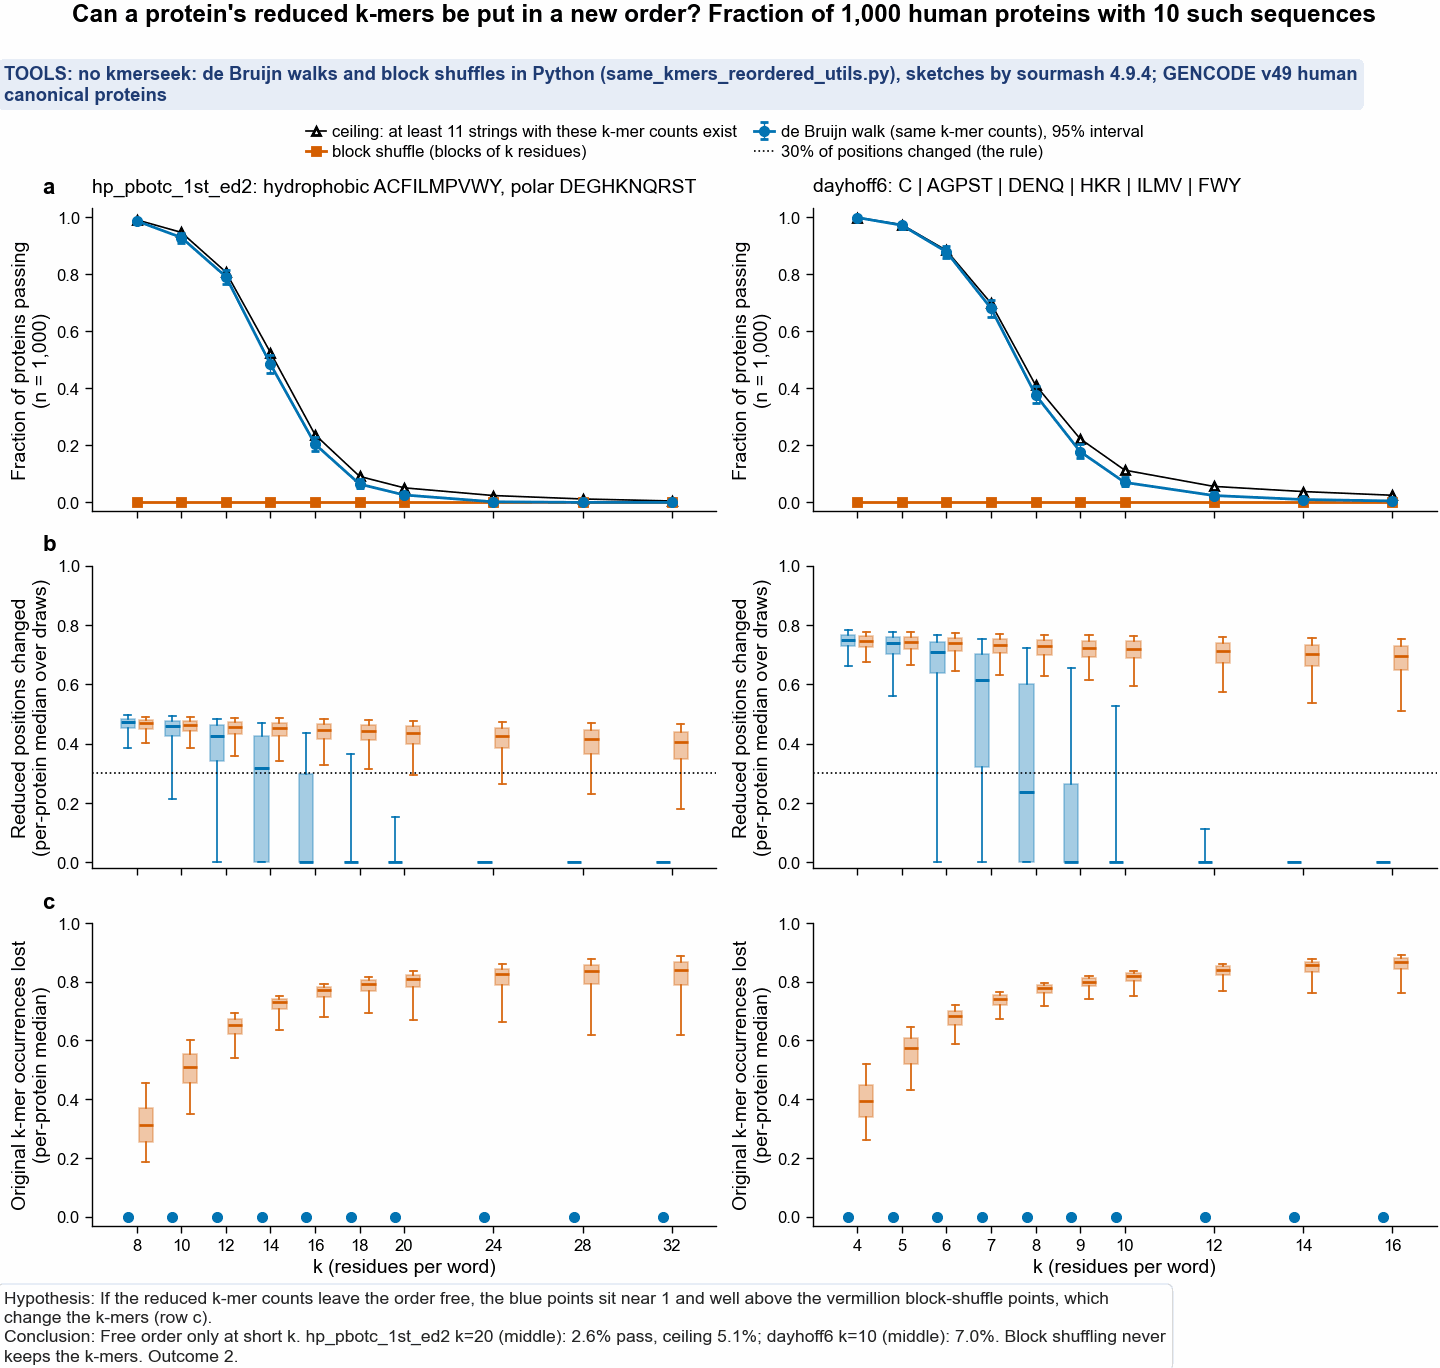

In [3]:
pf.use_style()
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 150, nrows=3, ncols=2, sharex="col")


def boxes(ax, data, ks, offset, colour, width):
    # one box per k: 25-75% box, median line, 5-95% whiskers, no outlier points
    bp = ax.boxplot(
        data,
        positions=np.array(ks) + offset,
        widths=width,
        whis=(5, 95),
        showfliers=False,
        patch_artist=True,
        manage_ticks=False,
    )
    for b in bp["boxes"]:
        b.set(facecolor=colour, alpha=0.35, edgecolor=colour, linewidth=0.6)
    for part in ("whiskers", "caps"):
        for l in bp[part]:
            l.set(color=colour, linewidth=0.6)
    for l in bp["medians"]:
        l.set(color=colour, linewidth=1.0)


for col, a in enumerate(ALPHABETS):
    s = summary.filter(pl.col("alphabet") == a).sort("k")
    ks = s["k"].to_list()
    step = min(np.diff(ks))
    ax = axs[0, col]
    ax.plot(
        ks,
        s["ceiling"],
        color="black",
        lw=0.6,
        marker="^",
        mfc="white",
        ms=3,
        label="ceiling: at least 11 strings with these k-mer counts exist",
    )
    ax.errorbar(
        ks,
        s["walk_pass"],
        yerr=[s["walk_pass"] - s["walk_pass_lo"], s["walk_pass_hi"] - s["walk_pass"]],
        color=WALK_COLOUR,
        marker="o",
        ms=3,
        lw=1,
        capsize=1.5,
        elinewidth=0.5,
        label="de Bruijn walk (same k-mer counts), 95% interval",
    )
    ax.plot(
        ks,
        s["shuffle_pass"],
        color=SHUFFLE_COLOUR,
        marker="s",
        ms=3,
        lw=1,
        label="block shuffle (blocks of k residues)",
    )
    ax.set_ylim(-0.03, 1.03)
    ax.set_ylabel("Fraction of proteins passing\n(n = 1,000)")
    ax.set_title(f"{a}: {CLASSES[a]}", loc="left")
    sub = per.filter(pl.col("alphabet") == a)
    walk = [
        sub.filter(pl.col("k") == k)["word_walk_median_changed"].to_numpy() for k in ks
    ]
    shuf = [
        sub.filter(pl.col("k") == k)["block_shuffle_median_changed"].to_numpy()
        for k in ks
    ]
    w = 0.32 * step
    ax = axs[1, col]
    boxes(ax, walk, ks, -0.2 * step, WALK_COLOUR, w)
    boxes(ax, shuf, ks, 0.2 * step, SHUFFLE_COLOUR, w)
    ax.axhline(
        run.MIN_CHANGED,
        color="black",
        lw=0.6,
        ls=":",
        label="30% of positions changed (the rule)",
    )
    ax.set_ylim(-0.02, 1.0)
    ax.set_ylabel("Reduced positions changed\n(per-protein median over draws)")
    ax = axs[2, col]
    kmer_loss = [
        sub.filter(pl.col("k") == k)["block_shuffle_median_word_change"].to_numpy()
        for k in ks
    ]
    boxes(ax, kmer_loss, ks, 0.2 * step, SHUFFLE_COLOUR, w)
    ax.plot(
        np.array(ks) - 0.2 * step,
        np.zeros(len(ks)),
        color=WALK_COLOUR,
        marker="o",
        ms=3,
        lw=0,
    )
    ax.set_ylim(-0.03, 1.0)
    ax.set_ylabel("Original k-mer occurrences lost\n(per-protein median)")
    ax.set_xlabel("k (residues per word)")
    ax.set_xticks(ks)
    ax.set_xticklabels([f"{k}" for k in ks])
for ax, letter in zip(axs[:, 0], "abc"):
    pf.panel_label(ax, letter)
pf.shared_legend(fig, ncol=2)
stem = "343_SF1_same_reduced_kmers_new_order_pass_fraction_gencode_v49_human"
pf.save(fig, FIG / f"{stem}_print", formats=("pdf", "png"))
mid_day = summary.filter(
    (pl.col("alphabet") == DAY) & (pl.col("k") == LOW_MID_HIGH[DAY][1])
).row(0, named=True)
stamp(
    fig,
    FIG / f"{stem}.png",
    title="Can a protein's reduced k-mers be put in a new order? Fraction of 1,000 human proteins with 10 such sequences",
    hypothesis=(
        "If the reduced k-mer counts leave the order free, the blue points sit near 1 and well above the "
        "vermillion block-shuffle points, which change the k-mers (row c)."
    ),
    conclusion=(
        f"Free order only at short k. {HP} k=20 (middle): {mid['walk_pass']:.1%} pass, ceiling "
        f"{mid['ceiling']:.1%}; {DAY} k=10 (middle): {mid_day['walk_pass']:.1%}. Block shuffling never "
        f"keeps the k-mers. Outcome {OUTCOME}."
    ),
    font_scale=0.7,
)
print(
    summary.select(
        "alphabet",
        "k",
        "walk_pass",
        "shuffle_pass",
        "ceiling",
        "walk_median_changed",
        "shuffle_median_changed",
        "shuffle_median_kmers_changed",
    )
)

## 2. What limits it: a long word is seen only once

A new order is possible only where the walk can branch, which needs a length-(k-1) word that
occurs at least twice in the reduced string. If no (k-1)-word repeats, the graph is a single
line and the original is the only string with these k-mer counts. The table gives, per k,
the fraction of proteins whose longest repeated reduced word is at least k-1 letters long
(a necessary condition for any second string) next to the exact BEST count.

In [4]:
def longest_repeat(s):
    # length of the longest word that occurs at least twice (overlaps allowed), binary search
    lo, hi = 0, len(s) - 1
    while lo < hi:
        m = (lo + hi + 1) // 2
        seen, rep = set(), False
        for i in range(len(s) - m + 1):
            w = s[i : i + m]
            if w in seen:
                rep = True
                break
            seen.add(w)
        lo, hi = (m, hi) if rep else (lo, m - 1)
    return lo


seqs = {h.split("|")[0]: s for h, s in run.read_fasta(run.FASTA)}
tested = per["ensp"].unique().to_list()
rep_rows = [
    {"ensp": e, "alphabet": a, "longest_repeat": longest_repeat(u.encode(seqs[e], a))}
    for e in tested
    for a in ALPHABETS
]
reps = pl.DataFrame(rep_rows)
ceil = (
    per.join(reps, on=["ensp", "alphabet"])
    .group_by("alphabet", "k")
    .agg(
        any_repeat_k_minus_1=(pl.col("longest_repeat") >= pl.col("k") - 1).mean(),
        more_than_one=(~pl.col("only_one")).mean(),
        at_least_11=pl.col("possible").mean(),
        walk_pass=pl.col("walk_ok").mean(),
    )
    .sort("alphabet", "k", descending=[True, False])
)
assert (ceil["more_than_one"] <= ceil["any_repeat_k_minus_1"] + 1e-9).all()
print(ceil)
print(
    "\nlongest repeated reduced word (letters), median and 90th percentile over the 1,000 proteins:"
)
print(
    reps.group_by("alphabet").agg(
        median=pl.col("longest_repeat").median(),
        p90=pl.col("longest_repeat").quantile(0.9),
    )
)

shape: (20, 6)
┌──────────────────┬─────┬──────────────────────┬───────────────┬─────────────┬───────────┐
│ alphabet         ┆ k   ┆ any_repeat_k_minus_1 ┆ more_than_one ┆ at_least_11 ┆ walk_pass │
│ ---              ┆ --- ┆ ---                  ┆ ---           ┆ ---         ┆ ---       │
│ str              ┆ i64 ┆ f64                  ┆ f64           ┆ f64         ┆ f64       │
╞══════════════════╪═════╪══════════════════════╪═══════════════╪═════════════╪═══════════╡
│ hp_pbotc_1st_ed2 ┆ 8   ┆ 1.000                ┆ 0.996         ┆ 0.990       ┆ 0.986     │
│ hp_pbotc_1st_ed2 ┆ 10  ┆ 0.997                ┆ 0.974         ┆ 0.946       ┆ 0.928     │
│ hp_pbotc_1st_ed2 ┆ 12  ┆ 0.976                ┆ 0.906         ┆ 0.807       ┆ 0.791     │
│ hp_pbotc_1st_ed2 ┆ 14  ┆ 0.899                ┆ 0.760         ┆ 0.525       ┆ 0.484     │
│ hp_pbotc_1st_ed2 ┆ 16  ┆ 0.748                ┆ 0.451         ┆ 0.237       ┆ 0.204     │
│ hp_pbotc_1st_ed2 ┆ 18  ┆ 0.513                ┆ 0.212         ┆

**Figure SF2. Longest repeated reduced word per protein**

How to read it. One histogram per alphabet: the length of the longest word that occurs at
least twice in each protein's reduced string. A protein can have a second string with the
same k-mer counts only when this length is at least k-1. The three vertical lines are k-1
for the low, middle and high k (dotted, solid, dashed; key in each panel). Bars on or right
of a line are proteins that may still be reordered at that k; bars left of it cannot be.

hp_pbotc_1st_ed2 beyond k-1 for low/mid/high k: {12: 0.976, 20: 0.281, 28: 0.061} | longer than 80: 4
dayhoff6 beyond k-1 for low/mid/high k: {6: 0.981, 10: 0.452, 14: 0.126} | longer than 80: 3


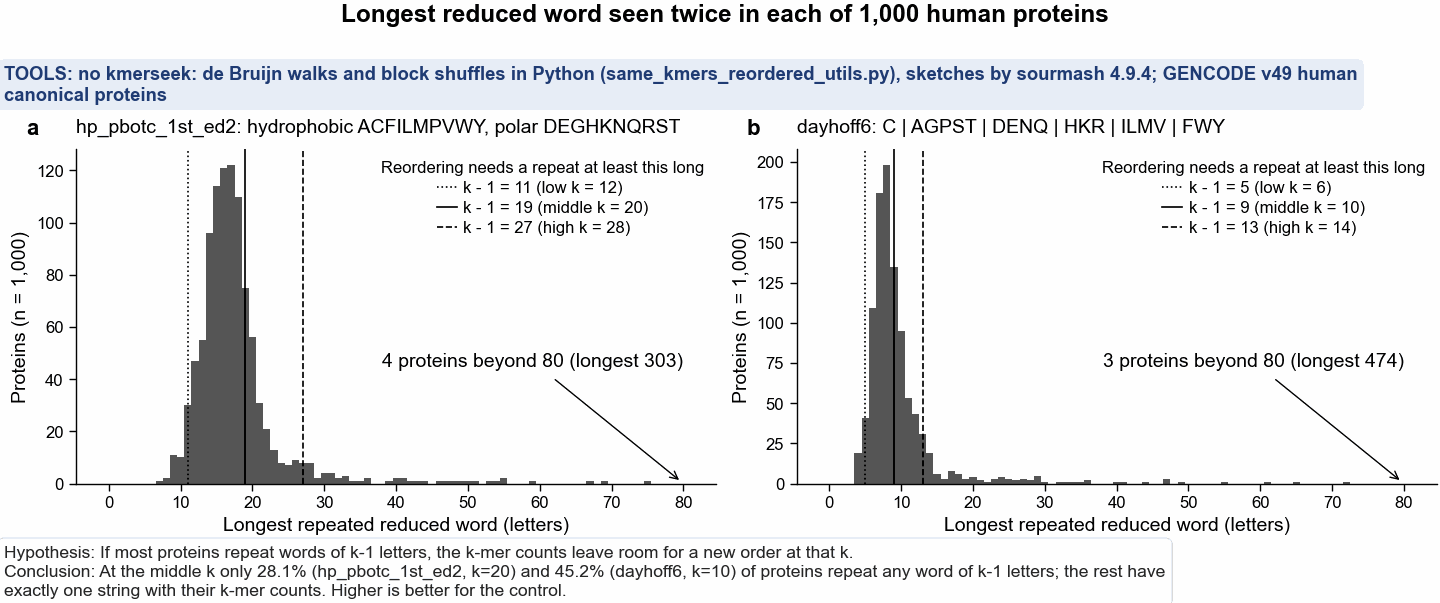

In [5]:
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=2)
REPEAT_AT_MID = {}
for ax, a in zip(axs, ALPHABETS):
    v = reps.filter(pl.col("alphabet") == a)["longest_repeat"].to_numpy()
    ax.hist(v, bins=np.arange(0, min(v.max(), 80) + 2) - 0.5, color="#555555")
    ax.set_title(f"{a}: {CLASSES[a]}", loc="left")
    for k, ls, word in zip(
        LOW_MID_HIGH[a], (":", "-", "--"), ("low", "middle", "high")
    ):
        ax.axvline(
            k - 1,
            color="black",
            lw=0.6,
            ls=ls,
            label=f"k - 1 = {k - 1} ({word} k = {k})",
        )
    ax.legend(
        loc="upper right",
        frameon=False,
        title="Reordering needs a repeat at least this long",
    )
    n_off = int((v > 80).sum())
    ax.annotate(
        f"{n_off} proteins beyond 80 (longest {v.max()})",
        xy=(80, 0),
        xytext=(80, ax.get_ylim()[1] * 0.35),
        ha="right",
        arrowprops=dict(arrowstyle="->", lw=0.5),
    )
    ax.set_xlabel("Longest repeated reduced word (letters)")
    ax.set_ylabel("Proteins (n = 1,000)")
    REPEAT_AT_MID[a] = float(np.mean(v >= LOW_MID_HIGH[a][1] - 1))
    print(
        a,
        "beyond k-1 for low/mid/high k:",
        {k: float(np.mean(v >= k - 1)) for k in LOW_MID_HIGH[a]},
        "| longer than 80:",
        int((v > 80).sum()),
    )
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
stem = "343_SF2_longest_repeated_reduced_word_gencode_v49_human"
pf.save(fig, FIG / f"{stem}_print", formats=("pdf", "png"))
stamp(
    fig,
    FIG / f"{stem}.png",
    title="Longest reduced word seen twice in each of 1,000 human proteins",
    hypothesis="If most proteins repeat words of k-1 letters, the k-mer counts leave room for a new order at that k.",
    conclusion=(
        f"At the middle k only {REPEAT_AT_MID[HP]:.1%} ({HP}, k=20) and {REPEAT_AT_MID[DAY]:.1%} "
        f"({DAY}, k=10) of proteins repeat any word of k-1 letters; the rest have exactly one string "
        "with their k-mer counts. Higher is better for the control."
    ),
    font_scale=0.7,
)

## 3. Worked example: BCL2

BCL2 (`ENSP00000329623`, 239 residues) in `hp_pbotc_1st_ed2`, at the largest k in the sweep
at which BCL2 passes the rule (chosen by that rule, not by eye). One new sequence is drawn
(seed 343) among those that change at least 30% of reduced positions. Printed: the amino-acid
and reduced strings, original above new, with a match line (`|` same, blank different); then
checks that the reduced k-mer counts and the sourmash FracMinHash sketch (scaled 1, so every
k-mer is kept, with counts) are identical byte for byte.

In [6]:
bcl2 = next(s for h, s in run.read_fasta(run.FASTA) if h.split("|")[6] == "BCL2")
red = u.encode(bcl2, HP)
ok_k = [
    k
    for k in sorted(summary.filter(pl.col("alphabet") == HP)["k"])
    if u.evaluate_protein(
        bcl2,
        HP,
        k,
        343,
        n_draws=run.N_DRAWS,
        n_needed=run.N_NEEDED,
        min_changed=run.MIN_CHANGED,
    )["word_walk_passing"]
    >= run.N_NEEDED
]
print(f"BCL2 passes in {HP} at k = {ok_k}")
K = max(ok_k)
g = u.WordGraph(red, K)
print(
    f"k = {K}: {np.exp(g.log_n_strings()):,.0f} strings share BCL2's reduced {K}-mer counts "
    f"(log10 = {g.log_n_strings() / np.log(10):.2f})"
)
rng = random.Random(343)
while True:
    alt_red = g.sample(rng)
    if u.fraction_changed(red, alt_red) >= run.MIN_CHANGED:
        break
alt = u.realize_protein(bcl2, red, alt_red)


def show(a, b, la, lb, width=60):
    for i in range(0, len(a), width):
        x, y = a[i : i + width], b[i : i + width]
        print(f"{la:>9} {i + 1:>4} {x}")
        print(f"{'':>14} {''.join('|' if p == q else ' ' for p, q in zip(x, y))}")
        print(f"{lb:>9} {i + 1:>4} {y}\n")


print("\nAmino acids (BCL2 above, new sequence below)\n")
show(bcl2, alt, "BCL2", "new")
print(f"Reduced, {HP} (h = ACFILMPVWY, p = DEGHKNQRST)\n")
show(red, alt_red, "BCL2", "new")
n_red = sum(p != q for p, q in zip(red, alt_red))
n_aa = sum(p != q for p, q in zip(bcl2, alt))
print(f"reduced positions changed: {n_red} of {len(red)} ({n_red / len(red):.1%})")
print(f"amino-acid positions changed: {n_aa} of {len(bcl2)} ({n_aa / len(bcl2):.1%})")
print(f"amino-acid counts identical: {Counter(bcl2) == Counter(alt)}")
print(
    f"first and last {K - 1} residues identical: "
    f"{bcl2[:K - 1] == alt[:K - 1] and bcl2[-(K - 1):] == alt[-(K - 1):]}"
)
print(f"new sequence encodes to the new reduced string: {u.encode(alt, HP) == alt_red}")

ck_a, ck_b = u.kmer_counts(red, K), u.kmer_counts(u.encode(alt, HP), K)
print(
    f"\nreduced {K}-mer multiset identical: {ck_a == ck_b} "
    f"({sum(ck_a.values())} occurrences, {len(ck_a)} distinct)"
)


def sketch(protein):
    # how kmerseek sketches a two-letter alphabet: pre-encode, then hash as protein, scaled=1
    mh = sourmash.MinHash(n=0, ksize=K, is_protein=True, scaled=1, track_abundance=True)
    mh.add_protein(u.encode(protein, HP))
    return mh


sa, sb = sketch(bcl2), sketch(alt)
ja = save_signatures_to_json([SourmashSignature(sa, name="BCL2")])
jb = save_signatures_to_json([SourmashSignature(sb, name="BCL2")])
print(
    f"FracMinHash sketch: {len(sa.hashes)} hashes; hashes and counts equal: {dict(sa.hashes) == dict(sb.hashes)}"
)
print(
    f"signature JSON byte-for-byte identical: {ja == jb}; "
    f"md5 {hashlib.md5(ja).hexdigest()} vs {hashlib.md5(jb).hexdigest()}"
)
print(
    f"amino-acid strings identical: {bcl2 == alt}; protein20 sketch identical: "
    f"{set(sourmash.MinHash(n=0, ksize=K, is_protein=True, scaled=1).seq_to_hashes(bcl2, is_protein=True)) == set(sourmash.MinHash(n=0, ksize=K, is_protein=True, scaled=1).seq_to_hashes(alt, is_protein=True))}"
)

BCL2 passes in hp_pbotc_1st_ed2 at k = [8, 10]
k = 10: 145,920 strings share BCL2's reduced 10-mer counts (log10 = 5.16)

Amino acids (BCL2 above, new sequence below)

     BCL2    1 MAHAGRTGYDNREIVMKYIHYKLSQRGYEWDAGDVGAAPPGAAPAPGIFSSQPGHTPHPA
               ||||||||||||||||||||||||       | | |||| | ||   || | |   ||| 
      new    1 MAHAGRTGYDNREIVMKYIHYKLSYWVQPRAAADGGAAPEGDAPGGPIFASPPAAAPHPS

     BCL2   61 ASRDPVARTSPLQTPAAPGAAAGPALSPVPPVVHLTLRQAGDDFSRRYRRDFAEMSSQLH
               |||  ||  ||| || ||||  |||  |  || |   ||| |  ||   | |   |    
      new   61 ASRLQVAVPSPLVTPGAPGAHTGPADLPRTPVQHSLTRQAFDYGSRADMRLFRFRSFVDA

     BCL2  121 LTPFTARGRFATVVEELFRDGVNWGRIVAFFEFGGVMCVESVNREMSPLVDNIALWMTEY
               | |  | | |||||  |   | ||||||   |  |||| | |       |  ||  | | 
      new  121 LFPEFAFGVFATVVMPLSLLGQNWGRIVHTTERWGVMCREYVLLWEFERVYLIADGMFES

     BCL2  181 LNRHLHTWIQDNGGWDAFVELYGPSMRPLFDFSWLSLKTLLSLALVGACITLGAYLGHK
                 |  | || || | || | |  |||||  |   |||||| | |  ||  |||||

## 4. Adversarial check by a second agent

A second Claude Code agent, in its own copy of the repository, tried to prove each claim
wrong with real inputs (scratch scripts kept outside the repo). Held means the attempt
failed to break the claim.

| Claim | Verdict | What was tried |
|---|---|---|
| BEST count and uniform draws are correct | Held | Count compared three ways on 1,910 strings (this code, an exact integer determinant, listing every walk): 0 disagreements. Chi-square on 12 cases with 24 to 144 strings: no string missed, smallest p = 0.024 of 12 tests. |
| Draws keep the k-mer counts, amino-acid counts and both ends | Held | 2,448 runs on 204 made-up proteins (poly-A, repeats, random), k from 2 to the protein length: 0 failures. |
| "Only one string" and "at least 11" are classified right despite floating-point determinants | Held | Exact integer counts for 12,400 table rows: 0 rows change class; largest error in the log count 6.8e-13. |
| Block shuffling is a fair baseline | Held for the conclusion | Block lengths k-1, k/2, 2k and 3 on 150 proteins at H/P k = 12 and 20: 0 of 150 kept the k-mers. A string with the exact k-mer counts is a walk in the same graph, so no method that keeps them can beat the ceiling. |
| BCL2 example | Held | Exact count at k = 10 is 145,920 (k = 12 has 5, so 10 is the largest passing k); 104 of 239 positions changed; signatures identical, and changing one letter makes them differ. sourmash 4.9.4 counts ksize in residues for protein input. |
| Result does not depend on the sample | Held | Another 300 proteins (seed 2026): H/P k = 20 pass 1.7%, ceiling 3.7%; Dayhoff k = 10 pass 7.0%, ceiling 11.0%. Still outcome 2. |
| Every sentence has a printed number | Held after fixes | "H/P k of 19 or more" now names its source; run time now quoted from the run's log. |

Two minor issues, both fixed or stated: the count fixes the first k-1 letters, which
undercounts only when the first and last (k-1)-words are the same (now said in section 1);
`WordGraph` fails at k = 1, which the sweep never uses.

## Summary and conclusions

### Background

kmerseek compares proteins through the length-k words of a reduced-alphabet string. This
notebook asks whether a real protein can be rewritten into a different sequence that has
exactly the same reduced words, each used as often as before, so that kmerseek's sketch
cannot tell the two apart. Such a sequence would be a control that changes only the order.

### Summary and conclusions

* At `hp_pbotc_1st_ed2` k = 20, only 2.6% of 1,000 human proteins (95% interval 1.8-3.8%)
  have 10 reorderings changing at least 30% of positions; the pre-registered outcome is 2.
* At H/P k = 20, 90.0% of human proteins have exactly one reduced string with their k-mer
  counts when the first k-1 letters are fixed. This is a property of full word counts, not proof
  that a sampled sketch determines the order.
* Reordering with identical k-mers works at short words: 79.1% of proteins pass at H/P
  k = 12 and 87.8% at `dayhoff6` k = 6.
* The limit is set by repeats: the median protein's longest repeated H/P word is 17 letters,
  and only 28.1% repeat any 19-letter word, which a new order at k = 20 needs.
* Block shuffling never meets the rule in any of the 20 settings, because it loses a median
  81% of the original reduced 20-mers at H/P k = 20.
* BCL2 at H/P k = 10 has 145,920 sequences with its exact reduced 10-mer counts; one changes
  104 of 239 positions and gives a byte-identical sourmash sketch.

**What to do with it.** Outcome 2. At the k kmerseek runs, a protein's reduced k-mer
counts and fixed first k-1 letters usually admit only one reduced string in this sample.
The tested construction therefore rarely supplies ten suitable controls at this k. A test of whether kmerseek depends on word order
has to change the words (shuffles, or k below the run k), or use the 2.6% of
proteins where these draws found ten suitable reorderings. This does not prove that all other
proteins lack such controls. Higher pass
fractions would have been better for the control; the drop is steep between k = 12 and
k = 20 for H/P and between k = 6 and k = 10 for Dayhoff.

### Analysis details

The pass fraction follows the ceiling closely at every k (H/P k = 20: 2.6% pass, ceiling
5.1%). This upper bound only counts distinct strings with fixed ends; it does not require
30% changed positions. The 2.5 percentage-point gap may reflect insufficient changed positions,
finite sampling, or both; the stored draws do not distinguish these explanations. Per-protein
change among the draws is a median 47% of reduced positions at H/P k = 8 and falls to 0 (the original
redrawn) once k is past the longest repeat. BCL2 passes at H/P k = 8 and 10 only.

### Supplementary information

* Code: `notebooks/same_kmers_reordered_utils.py` (graph, BEST count, uniform draws,
  amino-acid assignment, block shuffle); tests in `tests/test_same_kmers_reordered_utils.py`
  compare count and draws with brute-force enumeration.
* Sweep: `scripts/run_nb343_same_kmers_reordered.py`, 1,000 proteins x 20 settings, 200 draws
  per construction, seeds fixed; output `tables/343_same_kmers_reordered_gencode_v49_human.tsv`
  and summary `tables/343_same_kmers_reordered_summary_gencode_v49_human.tsv`.
* Figures: `figures/343_SF1_same_reduced_kmers_new_order_pass_fraction_gencode_v49_human.png`,
  `figures/343_SF2_longest_repeated_reduced_word_gencode_v49_human.png` (and `_print` PDFs).
* sourmash 4.9.4, scaled 1 with counts, the pre-encoded H/P string hashed as protein.

### References

* van Aardenne-Ehrenfest, T., and N. G. de Bruijn. "Circuits and Trees in Oriented Linear
  Graphs." *Simon Stevin* 28 (1951): 203-17. (BEST theorem; DOI not checked.)
* Wilson, D. B. "Generating Random Spanning Trees More Quickly than the Cover Time."
  *Proceedings of the 28th Annual ACM Symposium on Theory of Computing* (1996): 296-303.
  (DOI not checked.)
* Kandel, D., Y. Matias, R. Unger, and P. Winkler. "Shuffling Biological Sequences."
  *Discrete Applied Mathematics* 71 (1996): 171-85. (Uniform k-let-preserving shuffles by
  the same Eulerian-path method; DOI not checked.)